# 02805 Project: Food.com recipe network

In [1]:
import os
import kagglehub
import pandas as pd

path = kagglehub.dataset_download("shuyangli94/food-com-recipes-and-user-interactions")

recipes = pd.read_csv(os.path.join(path, "RAW_recipes.csv"))
interactions = pd.read_csv(os.path.join(path, "RAW_interactions.csv"))
print(recipes.shape, interactions.shape)

100%|██████████| 267M/267M [00:25<00:00, 10.9MB/s] 

Extracting files...


(231637, 12) (1132367, 5)


## Step 1: Look at the raw data

Before we change anything, we look at what the data contains and list the problems. Each cleaning step later should fix one of these problems.

### Recipes

In [2]:
recipes.info()

<class 'pandas.DataFrame'>
RangeIndex: 231637 entries, 0 to 231636
Data columns (total 12 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   name            231636 non-null  str  
 1   id              231637 non-null  int64
 2   minutes         231637 non-null  int64
 3   contributor_id  231637 non-null  int64
 4   submitted       231637 non-null  str  
 5   tags            231637 non-null  str  
 6   nutrition       231637 non-null  str  
 7   n_steps         231637 non-null  int64
 8   steps           231637 non-null  str  
 9   description     226658 non-null  str  
 10  ingredients     231637 non-null  str  
 11  n_ingredients   231637 non-null  int64
dtypes: int64(5), str(7)
memory usage: 21.2 MB


In [3]:
recipes.isna().sum()

name                 1
id                   0
minutes              0
contributor_id       0
submitted            0
tags                 0
nutrition            0
n_steps              0
steps                0
description       4979
ingredients          0
n_ingredients        0
dtype: int64

Numeric columns: are there impossible values?

In [4]:
recipes[["minutes", "n_steps", "n_ingredients"]].describe()

,minutes,n_steps,n_ingredients
count,2.316370e+05,231637.000000,231637.000000
mean,9.398546e+03,9.765499,9.051153
std,4.461963e+06,5.995128,3.734796
min,0.000000e+00,0.000000,1.000000
25%,2.000000e+01,6.000000,6.000000
50%,4.000000e+01,9.000000,9.000000
75%,6.500000e+01,12.000000,11.000000
max,2.147484e+09,145.000000,43.000000


The ingredients look like lists, but are they?

In [5]:
print(recipes["ingredients"].iloc[0])
print(type(recipes["ingredients"].iloc[0]))

['winter squash', 'mexican seasoning', 'mixed spice', 'honey', 'butter', 'olive oil', 'salt']
<class 'str'>


### Reviews (interactions)

In [6]:
interactions.info()

<class 'pandas.DataFrame'>
RangeIndex: 1132367 entries, 0 to 1132366
Data columns (total 5 columns):
 #   Column     Non-Null Count    Dtype
---  ------     --------------    -----
 0   user_id    1132367 non-null  int64
 1   recipe_id  1132367 non-null  int64
 2   date       1132367 non-null  str  
 3   rating     1132367 non-null  int64
 4   review     1132198 non-null  str  
dtypes: int64(3), str(2)
memory usage: 43.2 MB


In [7]:
interactions["rating"].value_counts().sort_index()

rating
0     60847
1     12818
2     14123
3     40855
4    187360
5    816364
Name: count, dtype: int64

In [8]:
print("Empty reviews:", interactions["review"].isna().sum())
print("Same user reviewing the same recipe twice:", interactions.duplicated(["user_id", "recipe_id"]).sum())

Empty reviews: 169
Same user reviewing the same recipe twice: 0


### Problems found

1. `ingredients` (and `tags`, `steps`, `nutrition`) are stored as text, not as lists.
2. `minutes` has impossible values: minimum 0, maximum about 2 billion.
3. Some recipes have 0 steps or only 1 ingredient.
4. 1 recipe has no name, and 4,979 have no description (not a problem for us).
5. `rating` = 0 occurs 60,847 times. On Food.com this means *no rating given*, not zero stars, so it must be treated as missing.
6. Ratings are very skewed: 816,364 of 1,132,367 (72 %) are 5 stars.
7. 169 reviews are empty. No user reviewed the same recipe twice.

## Step 2: Text columns to lists

`ingredients`, `tags`, `steps` and `nutrition` look like lists but are stored as text, e.g. `"['egg', 'flour']"`. `ast.literal_eval` reads the text as Python and turns it into a real list.

In [9]:
import ast

for col in ["ingredients", "tags", "steps", "nutrition"]:
    recipes[col] = recipes[col].apply(ast.literal_eval)

print(recipes["ingredients"].iloc[0])
print(type(recipes["ingredients"].iloc[0]))

['winter squash', 'mexican seasoning', 'mixed spice', 'honey', 'butter', 'olive oil', 'salt']
<class 'list'>


Check: the length of each new list should match the counts that came with the data.

In [10]:
print("ingredients match n_ingredients:", (recipes["ingredients"].str.len() == recipes["n_ingredients"]).all())
print("steps match n_steps:", (recipes["steps"].str.len() == recipes["n_steps"]).all())

ingredients match n_ingredients: True
steps match n_steps: True


## Step 3: Impossible cooking times and broken recipes

### Cooking time

First we look at the extreme values before deciding what is wrong.

In [11]:
m = recipes["minutes"]
print("0 minutes:", (m == 0).sum())
print("More than 1 day:", (m > 24 * 60).sum())
print("More than 1 year:", (m > 365 * 24 * 60).sum())

recipes.loc[m > 24 * 60, ["name", "minutes"]].sample(8, random_state=0)

0 minutes: 1094
More than 1 day: 2000
More than 1 year: 2


,name,minutes
52054,chocolate covered bourbon cherries,5820
136866,miss yum yum sauce,1445
130993,marinated mushrooms my way,1450
91109,george washington s eggnog i m not kidding,10125
198608,springtime layered spinach salad,1500
135413,middle eastern vinegar,20161
173141,rheinischer sauerbraten,5805
147742,on sale refrigerator relish,1455


In [12]:
recipes.loc[m == 0, ["name", "minutes", "n_steps"]].sample(5, random_state=0)

,name,minutes,n_steps
159449,pickled peaches or pears,0,5
153390,paruppu thogayal,0,3
153923,pasta with blue cheese sauce,0,8
203213,summer sausage,0,6
101007,gypsy tart ii,0,6


Recipes over one day are mostly real: marinating, pickling, curing (e.g. sauerbraten takes 4 days). So we keep them. Only two kinds of values are clearly wrong:

- **0 minutes**: no real recipe takes 0 minutes.
- **More than one year**: e.g. 2,147,483,647 minutes, which is the largest number a 32-bit integer can hold, so it is a technical error.

We set these to missing (`NaN`) instead of removing the recipes, because their ingredients are still fine.

In [13]:
bad = (recipes["minutes"] == 0) | (recipes["minutes"] > 365 * 24 * 60)
recipes.loc[bad, "minutes"] = None
print("Cooking times set to missing:", bad.sum())

Cooking times set to missing: 1096


### Recipes with no steps or very few ingredients

In [14]:
print("Recipes with 0 steps:", (recipes["n_steps"] == 0).sum())
print(recipes["n_ingredients"].value_counts().sort_index().head(3))

recipes.loc[recipes["n_ingredients"] <= 2, ["name", "ingredients"]].sample(8, random_state=0)

Recipes with 0 steps: 1
n_ingredients
1      25
2    2127
3    6800
Name: count, dtype: int64


,name,ingredients
175625,roasted garlic oil,"[garlic cloves, olive oil]"
226239,white chocolate fondant,"[white chocolate, light corn syrup]"
75549,easy cheesy hot dogs,"[hot dogs, cheese]"
30037,broth simmered rice,"[chicken broth, long-grain white rice]"
18898,batido de mango mango shake,"[mango pulp, milk]"
222831,venison beef veal or lamb canned,"[beef, salt]"
28367,breadstick bones,"[refrigerated breadstick dough, butter]"
48984,chipotles smoked jalapenos,"[jalapenos, wood chips]"


Only one recipe has no steps at all, so it is not a real recipe and we remove it.

Recipes with 1 or 2 ingredients are real dishes (garlic oil, mango shake), not errors, so we keep them here. Whether they can get links is decided later, when we define the network.

In [15]:
n_before = len(recipes)
recipes = recipes[recipes["n_steps"] > 0].reset_index(drop=True)
print(f"Removed {n_before - len(recipes)} recipe, {len(recipes):,} left")

Removed 1 recipe, 231,636 left


## Step 4: Clean the reviews

- **Rating 0**: on Food.com a review can be written without giving stars, and then the rating is stored as 0. So 0 means *no rating*, not *zero stars*, and we set it to missing. We keep the review text.
- **Empty reviews**: a review without text gives us nothing to analyse, so we remove it.
- **Unknown recipes**: reviews of recipes that are no longer in `recipes` (e.g. the one we removed in step 3) are removed.

In [16]:
import numpy as np

interactions["rating"] = interactions["rating"].replace(0, np.nan)
print("Ratings set to missing:", interactions["rating"].isna().sum())

Ratings set to missing: 60847


In [17]:
n_before = len(interactions)
interactions = interactions[interactions["review"].notna()]
interactions = interactions[interactions["recipe_id"].isin(recipes["id"])]
interactions = interactions.reset_index(drop=True)
print(f"Removed {n_before - len(interactions):,} reviews, {len(interactions):,} left")

Removed 171 reviews, 1,132,196 left


Check: the rating distribution without the zeros.

In [18]:
interactions["rating"].value_counts(normalize=True).sort_index().round(3)

rating
1.0    0.012
2.0    0.013
3.0    0.038
4.0    0.175
5.0    0.762
Name: proportion, dtype: float64

## Step 5: Remove duplicates

We look for three kinds of duplicates:

1. The same recipe id twice.
2. Recipes with exactly the same ingredients, often the same recipe uploaded again under a new name.
3. Duplicate reviews.

In [19]:
ingr_set = recipes["ingredients"].apply(lambda xs: tuple(sorted(set(xs))))

print("Same id:", recipes["id"].duplicated().sum())
print("Same name and same ingredients:", pd.DataFrame({"n": recipes["name"], "i": ingr_set}).duplicated().sum())
print("Same ingredients:", ingr_set.duplicated().sum())

Same id: 0
Same name and same ingredients: 17
Same ingredients: 2265


Examples of recipes with the same ingredients:

In [20]:
same = recipes[ingr_set.duplicated(keep=False)].assign(ingr_set=ingr_set)
same.sort_values("ingr_set")[["name", "ingredients"]].head(10)

,name,ingredients
49374,chocolate banana smoothie with a hint of peanut,"[1% low-fat milk, chocolate flavor instant pud..."
49113,choco nana mixer,"[1% low-fat milk, chocolate flavor instant pud..."
118439,kmac s quick delicious smoothie,"[banana, strawberries, 1% low-fat milk, peanut..."
155749,peanut butter banana break shake smoothie,"[banana, 1% low-fat milk, strawberries, ice cu..."
103692,healthy one pot meal,"[olive oil, onion, 93% lean ground beef, mince..."
20461,beef noodle one pot meal,"[olive oil, onion, 93% lean ground beef, mince..."
39886,cheesecake pecan pie,"[cream cheese, egg, sugar, salt, vanilla, 9-in..."
142399,mystery pecan pie,"[eggs, sugar, light corn syrup, vanilla, cream..."
225236,weight watchers juicy hamburgers,"[cooking spray, 93% lean ground beef, worceste..."
115710,juicy hamburgers,"[cooking spray, 93% lean ground beef, worceste..."


Most of these are clearly the same recipe (e.g. *juicy hamburgers* and *weight watchers juicy hamburgers* with the same 7 ingredients). In the network they would get a link with similarity 1 that only reflects a re-upload, and their reviews are split between the copies.

We keep **one** recipe per ingredient list: the one with the most reviews, because the number of reviews decides which recipes become nodes in the next step. The reviews of the removed copies are removed too.

Note: here two lists only count as the same if the ingredient names are written exactly the same. When we clean the ingredient names later (`eggs` → `egg`), more duplicates may appear, so we check again then.

In [21]:
reviews_per_recipe = interactions.groupby("recipe_id").size()
recipes["n_reviews"] = recipes["id"].map(reviews_per_recipe).fillna(0).astype(int)

n_before = len(recipes)
recipes = (recipes.assign(ingr_set=ingr_set)
                  .sort_values("n_reviews", ascending=False)
                  .drop_duplicates("ingr_set")
                  .drop(columns="ingr_set")
                  .sort_index()
                  .reset_index(drop=True))
print(f"Removed {n_before - len(recipes):,} duplicate recipes, {len(recipes):,} left")

n_before = len(interactions)
interactions = interactions[interactions["recipe_id"].isin(recipes["id"])].reset_index(drop=True)
print(f"Removed {n_before - len(interactions):,} reviews of the removed copies, {len(interactions):,} left")

Removed 2,265 duplicate recipes, 229,371 left
Removed 7,286 reviews of the removed copies, 1,124,910 left


### Duplicate reviews

No user reviewed the same recipe twice (step 1). But some users wrote exactly the same text on different recipes:

In [22]:
same_text = interactions[interactions.duplicated(["user_id", "review"], keep=False)]
print("Reviews with the same text by the same user:", len(same_text))
same_text["review"].value_counts().head(8)

Reviews with the same text by the same user: 1683


review
Yum!                                         63
Delicious!                                   57
Yum.                                         39
Excellent!                                   36
Very good!                                   26
Very Good!                                   25
Enjoyed the flavours, thanks for sharing.    20
Very Good.                                   18
Name: count, dtype: int64

These are short, generic reviews like *Yum!* and *Delicious!*. They are real reviews of different recipes, not copies, so we keep them.

## Step 6: Choose which recipes become nodes

The course page (week 8) says *"A few hundred to a few thousand nodes is the sweet spot"* and that above 10,000 nodes the project becomes about managing compute. It also asks for *text on the nodes*. So we keep recipes that have many reviews: they are recipes people actually cook, and each has enough review text.

First we see how many recipes we get with different minimum numbers of reviews.

In [23]:
reviews_per_recipe = interactions.groupby("recipe_id").size()

rows = []
for k in [10, 20, 30, 50, 100]:
    kept = reviews_per_recipe[reviews_per_recipe >= k]
    rows.append({"min_reviews": k,
                 "recipes": len(kept),
                 "share_of_recipes": len(kept) / len(recipes),
                 "share_of_reviews": kept.sum() / len(interactions)})

pd.DataFrame(rows).round(3)

,min_reviews,recipes,share_of_recipes,share_of_reviews
0,10,21287,0.093,0.535
1,20,7952,0.035,0.378
2,30,4467,0.019,0.304
3,50,2157,0.009,0.228
4,100,785,0.003,0.146


We choose **at least 30 reviews**: about 4,500 recipes is in the course's sweet spot, and every recipe has enough review text to analyse.

In [24]:
MIN_REVIEWS = 30

all_recipes = recipes   # keep the full set, to compare with below
recipes = recipes[recipes["n_reviews"] >= MIN_REVIEWS].reset_index(drop=True)
interactions = interactions[interactions["recipe_id"].isin(recipes["id"])].reset_index(drop=True)

print(f"Recipes: {len(recipes):,}")
print(f"Reviews: {len(interactions):,}")
print(f"Users:   {interactions['user_id'].nunique():,}")

Recipes: 4,467
Reviews: 342,496
Users:   109,343


**Limitation:** we now study *popular* recipes, not all recipes on Food.com. To see how they differ, we compare them with all recipes:

In [ ]:
all_recipes["year"] = all_recipes["submitted"].str[:4].astype(int)
recipes["year"] = recipes["submitted"].str[:4].astype(int)

cols = ["n_ingredients", "n_steps", "minutes", "year"]
pd.DataFrame({"all recipes": all_recipes[cols].median(), # median over recipes
              "kept (>= 30 reviews)": recipes[cols].median()})

,all recipes,kept (>= 30 reviews)
n_ingredients,9.0,8.0
n_steps,9.0,8.0
minutes,40.0,40.0
year,2007.0,2003.0


The kept recipes are a bit simpler (8 vs 9 ingredients and steps), take the same time, but were submitted about **four years earlier** (median 2003 vs 2007).

**Note: rich get richer.** This fits the idea of preferential attachment from week 2 (Barabási–Albert): a recipe that already has many reviews is shown higher on the site and in searches, so it is found and reviewed by even more people. Early recipes have had the longest time to collect reviews, and every lead they get is reinforced, just like the oldest nodes become hubs in the BA model.

But we have not shown that this mechanism is at work. The age difference is also explained by time alone: an older recipe has simply been online longer. To separate the two, we would have to look at how fast recipes collect reviews over time. In the report we can therefore only say that the age difference is *consistent with* rich get richer, and that our sample is biased towards old, popular recipes.

## Step 7: Ingredient names

The links in our network will be based on shared ingredients, so two recipes that both use eggs must also *write* eggs the same way. First we look at how the names look, before we change anything.

In [26]:
from collections import Counter

ingredient_counts = Counter(x for xs in recipes["ingredients"] for x in xs)
print("Different ingredient names:", len(ingredient_counts))
print("Names used in only one recipe:", sum(c == 1 for c in ingredient_counts.values()))

ingredient_counts.most_common(30)

Different ingredient names: 3111
Names used in only one recipe: 1313


[('salt', 2008),
 ('butter', 1296),
 ('sugar', 1001),
 ('water', 801),
 ('onion', 742),
 ('eggs', 737),
 ('flour', 688),
 ('milk', 589),
 ('olive oil', 547),
 ('brown sugar', 488),
 ('pepper', 471),
 ('garlic', 457),
 ('garlic cloves', 455),
 ('baking powder', 454),
 ('all-purpose flour', 446),
 ('vanilla', 399),
 ('baking soda', 399),
 ('egg', 398),
 ('garlic powder', 368),
 ('parmesan cheese', 356),
 ('vegetable oil', 353),
 ('black pepper', 315),
 ('salt and pepper', 296),
 ('cinnamon', 278),
 ('sour cream', 266),
 ('paprika', 246),
 ('lemon juice', 244),
 ('cream cheese', 235),
 ('soy sauce', 229),
 ('oil', 229)]

Variants of the same ingredient, e.g. everything that contains *egg* or *garlic*:

In [27]:
for word in ["egg", "garlic", "butter", "pepper"]:
    variants = {name: c for name, c in ingredient_counts.items() if word in name}
    print(word, "->", len(variants), "names:", sorted(variants, key=variants.get, reverse=True)[:12])
    print()

egg -> 32 names: ['eggs', 'egg', 'egg whites', 'egg yolks', 'egg white', 'egg noodles', 'egg yolk', 'hard-boiled eggs', 'eggplant', 'egg substitute', 'wide egg noodles', 'parmigiano-reggiano cheese']

garlic -> 36 names: ['garlic', 'garlic cloves', 'garlic powder', 'garlic clove', 'garlic salt', 'fresh garlic', 'minced garlic cloves', 'fresh garlic cloves', 'minced garlic clove', 'instant minced garlic', 'garlic butter', 'chili-garlic sauce']

butter -> 56 names: ['butter', 'unsalted butter', 'buttermilk', 'peanut butter', 'creamy peanut butter', 'butternut squash', 'smooth peanut butter', 'salted butter', 'real butter', 'crunchy peanut butter', 'butterscotch chips', 'chunky peanut butter']

pepper -> 124 names: ['pepper', 'black pepper', 'salt and pepper', 'cayenne pepper', 'fresh ground black pepper', 'ground black pepper', 'crushed red pepper flakes', 'red pepper flakes', 'fresh ground pepper', 'green pepper', 'green bell pepper', 'red bell pepper']



### The plan

Ingredient names are short texts, so we clean them with the preprocessing ideas from week 5. Every step can also remove useful information, so we do one step at a time and count how many names are left after each step.

1. **Remove describing words** (*fresh, minced, chopped, large, unsalted, ...*), like a stopword list, plus brand names (*lipton, swanson, ...*) and sizes (*8-inch*, *95%*). We only remove whole words, so *peanut butter* and *eggplant* are never touched. A few names would change meaning if a word were removed (*dry mustard* is mustard powder, not mustard), so they are fixed first (`KEEP`). *lemon, juice of* is rewritten to *lemon juice*.
2. **Plural to singular** (*eggs → egg*, *tomatoes → tomato*, *leaves → leaf*), a simple form of lemmatization. We only change a word if the singular form also exists as an ingredient name in the data, so *molasses* stays *molasses*. We do this after step 1, because *fresh garlic cloves* first has to become *garlic cloves* before it can become *garlic clove*.
3. **A hand-made list of synonyms** (*garlic clove → garlic*, *whipping cream → heavy cream*), splitting combined ingredients (*salt and pepper → salt* + *pepper*), leaves of herbs count as the herb (*thyme leaf → thyme*, but *bay leaf* stays), and **removing things that are not food** (aluminum foil, toothpicks, skewers).

The rules were made in two rounds: a first version, and then a second round after we read through all the clean names and the hand-check samples (see below). Many synonyms and the `KEEP` names come from that second round.

In [ ]:
import re

# Step 1: names where removing a word would change the ingredient, so they are fixed first
KEEP = {
    "dry mustard": "mustard powder", "dried mustard": "mustard powder", "ground mustard": "mustard powder",
    "dry milk": "milk powder", "powdered milk": "milk powder", "nonfat dry milk": "milk powder",
    "lean ground meat": "ground meat", "ground meat": "ground meat",
    "1% fat cottage cheese": "cottage cheese",
}

# Step 1: describing words, brand names and phrases that do not change what the ingredient is
PHRASES = ["extra virgin", "extra-virgin", "low sodium", "reduced sodium", "low fat", "fat free",
           "reduced fat", "all-purpose", "all purpose", "freshly ground", "fresh ground",
           "old fashioned", "old-fashioned", "whole grain", "whole-grain", "head of", "ear of", "ears of",
           # brand names (not kept where the brand is the product: velveeta, cool whip, bisquick, jell-o)
           "campbell's", "kraft", "nestle", "toll house", "pillsbury", "hidden valley", "jimmy dean",
           "hellmann's", "hellmanns", "philadelphia", "heinz", "lea & perrins", "betty crocker", "hormel",
           "lipton", "knorr", "mccormick's", "mccormick", "kikkoman's", "kikkoman", "swanson", "old el paso"]
WORDS = {"fresh", "freshly", "minced", "chopped", "diced", "sliced", "grated", "shredded", "crushed",
         "large", "small", "medium", "unsalted", "salted", "ground", "finely", "coarsely", "boneless",
         "skinless", "lean", "extra", "virgin", "granulated", "kosher", "plain", "pure", "cooked",
         "uncooked", "frozen", "canned", "softened", "melted", "beaten", "peeled", "pitted", "boiling",
         "cold", "warm", "lukewarm", "packed", "light", "dark", "sharp", "mild", "organic", "baby",
         "low-fat", "fat-free", "nonfat", "non-fat", "reduced-fat", "low-sodium", "reduced-sodium",
         "whole", "raw", "dried", "dry",
         "semi-sweet", "semisweet", "unsweetened", "miniature", "mini", "rolled", "quick-cooking", "quick",
         "creamy", "chunky", "crunchy", "smooth", "slivered", "coarse", "cracked", "unbleached", "bleached",
         "wide", "fillet", "fillets", "original", "jumbo"}


# sizes and percentages like 8-inch, 9", 95%, 10-minute (but not 7-up, v8, a.1.)
SIZE = re.compile(r'^\d+(%|"|-inch|-minute)$')


def remove_describing_words(name):
    if name in KEEP:
        return KEEP[name]
    # "lemon, juice of" -> "lemon juice", "limes, zest of" -> "lime zest"
    m = re.match(r"^(\w+?)s?, (juice|zest|rind|juice and zest|juice and rind) of$", name)
    if m:
        fruit, part = m.groups()
        parts = {"juice": "juice", "zest": "zest", "rind": "zest"}
        return "; ".join(f"{fruit} {parts[p]}" for p in part.split(" and "))
    for phrase in PHRASES:
        name = re.sub(rf"\b{re.escape(phrase)}(?!\w)", " ", name)
    words = [w for w in name.split() if w not in WORDS and not SIZE.match(w)]
    return " ".join(words) if words else name      # never remove everything


# Step 2: plural -> singular, only if the singular form exists in the data
def to_singular(name, known_names):
    if name.endswith("'s"):                        # m&m's, not a plural
        return name
    if name.endswith("leaves"):                    # thyme leaves -> thyme leaf
        return name[:-6] + "leaf"
    for plural, singular in [("ies", "y"), ("oes", "o"), ("ches", "ch"), ("ves", "f"), ("s", "")]:
        if name.endswith(plural) and not name.endswith("ss"):
            candidate = name[: -len(plural)] + singular
            if candidate in known_names:
                return candidate
    return name


# Step 3: synonyms; "; " splits one name into two ingredients
SYNONYMS = {
    "garlic clove": "garlic",
    "clove garlic": "garlic",
    "black pepper": "pepper",
    "salt and pepper": "salt; pepper",
    "salt & pepper": "salt; pepper",
    "salt and black pepper": "salt; pepper",
    "salt & black pepper": "salt; pepper",
    "sea salt": "salt",
    "table salt": "salt",
    "white sugar": "sugar",
    "confectioners' sugar": "powdered sugar",
    "icing sugar": "powdered sugar",
    "vanilla extract": "vanilla",
    "oil": "vegetable oil",
    "cooking oil": "vegetable oil",
    "salad oil": "vegetable oil",
    "scallion": "green onion",
    "spring onion": "green onion",
    "catsup": "ketchup",
    "chicken breast half": "chicken breast",
    # found when we read through the clean names!!!!
    "cayenne": "cayenne pepper",
    "jalapeno pepper": "jalapeno",
    "celery rib": "celery",
    "celery stalk": "celery",
    "dill weed": "dill",
    "basil leaf": "basil",
    "oregano leaf": "oregano",
    "oregano leaves": "oregano",
    "parsley leaf": "parsley",
    "parsley leaves": "parsley",
    "parsley flakes": "parsley",
    "spinach leaf": "spinach",
    "spinach leaves": "spinach",
    "cocoa powder": "cocoa",
    "whipping cream": "heavy cream",
    "heavy whipping cream": "heavy cream",
    "half-and-half cream": "half-and-half",
    "condensed cream of mushroom soup": "cream of mushroom soup",
    "condensed cream of chicken soup": "cream of chicken soup",
    "condensed cream of celery soup": "cream of celery soup",
    "condensed cream of tomato soup": "cream of tomato soup",
    "elbow macaroni": "macaroni",
    "feta": "feta cheese",
    "cheddar": "cheddar cheese",
    "parmesan": "parmesan cheese",
    "mozzarella": "mozzarella cheese",
    "taco seasoning mix": "taco seasoning",
    "hot water": "water",
    "ice water": "water",
    "kernel corn": "corn",
    "corn kernel": "corn",
    "apple cider vinegar": "cider vinegar",
    "chicken bouillon cube": "chicken bouillon",
    "chicken bouillon granules": "chicken bouillon",
    "beef bouillon cube": "beef bouillon",
    "beef bouillon granules": "beef bouillon",
    "bicarbonate of soda": "baking soda",
    "italian seasoned breadcrumbs": "italian breadcrumbs",
    "italian style breadcrumbs": "italian breadcrumbs",
    "pecan half": "pecans",
    "pecan halves": "pecans",
    "rotel": "rotel tomatoes",
    "ro-tel tomatoes": "rotel tomatoes",
    "chocolate chip": "chocolate chips",
    "powdered milk": "milk powder",
    "grain mustard": "mustard",
    "gingerroot": "ginger",
    "milk ricotta cheese": "ricotta cheese",
}

# Step 3: leaves of herbs count as the herb (thyme leaf -> thyme), except leaves that are an ingredient themselves
LEAF_NAMES = {"bay leaf", "curry leaf", "banana leaf", "kaffir lime leaf", "lime leaf", "grape leaf"}

# Not food: kitchen equipment that some recipes list as an ingredient
NOT_FOOD = {"aluminum foil", "reynolds wrap foil", "wooden skewer", "bamboo skewer", "toothpick", "paraffin wax",
            "parchment paper", "wax paper", "plastic wrap", "oven cooking bag", "jar", "tall slender 4 cup container"}

Apply the three steps to every different raw name, and count how many different names are left after each step.

In [29]:
raw_names = set(x for xs in recipes["ingredients"] for x in xs)

# names known in the full data (all recipes), so more singular forms can be found
known_names = set(x for xs in all_recipes["ingredients"] for x in xs)
known_names |= set(remove_describing_words(x) for x in known_names)


def clean_name(name):
    result = []
    for part in remove_describing_words(name).split("; "):    # step 1
        part = to_singular(part, known_names)                  # step 2
        for p in SYNONYMS.get(part, part).split("; "):         # step 3 (one name can become two)
            if p.endswith(" leaf") and p not in LEAF_NAMES:
                p = p[:-5]
            if p not in NOT_FOOD:
                result.append(p)
    return result


names1 = set(part for x in raw_names for part in remove_describing_words(x).split("; "))
names2 = set(to_singular(x, known_names) for x in names1)
names3 = set(part for x in raw_names for part in clean_name(x))
print(f"Raw names:              {len(raw_names):,}")
print(f"1. describing words:    {len(names1):,}")
print(f"2. plural -> singular:  {len(names2):,}")
print(f"3. synonyms, not food:  {len(names3):,}")

Raw names:              3,111
1. describing words:    2,408
2. plural -> singular:  2,211
3. synonyms, not food:  2,129


In [30]:
clean = {x: clean_name(x) for x in raw_names}
recipes["ingr_clean"] = recipes["ingredients"].apply(
    lambda xs: sorted(set(part for x in xs for part in clean[x])))   # each ingredient once per recipe

Counter(recipes["ingr_clean"].explode()).most_common(30)

[('salt', 2536),
 ('pepper', 1547),
 ('butter', 1435),
 ('sugar', 1258),
 ('flour', 1154),
 ('egg', 1131),
 ('garlic', 1097),
 ('water', 945),
 ('onion', 940),
 ('milk', 660),
 ('olive oil', 646),
 ('vanilla', 632),
 ('vegetable oil', 614),
 ('brown sugar', 576),
 ('baking powder', 454),
 ('baking soda', 401),
 ('cinnamon', 388),
 ('lemon juice', 372),
 ('garlic powder', 368),
 ('parsley', 368),
 ('parmesan cheese', 364),
 ('chicken breast', 341),
 ('cheddar cheese', 312),
 ('tomato', 312),
 ('sour cream', 295),
 ('green onion', 280),
 ('soy sauce', 272),
 ('oregano', 270),
 ('chicken broth', 256),
 ('cream cheese', 253)]

**Names used in only one recipe** (hapax, week 5). Such a name can never create a link, because a link needs two recipes that share an ingredient. How many are there before and after cleaning, and how many of the raw ones got a partner?

In [31]:
raw_counts = Counter(x for xs in recipes["ingredients"] for x in set(xs))
clean_counts = Counter(x for xs in recipes["ingr_clean"] for x in xs)

raw_alone = [x for x, c in raw_counts.items() if c == 1]
got_partner = [x for x in raw_alone if any(clean_counts[part] > 1 for part in clean[x])]

print(f"Before cleaning: {len(raw_alone):,} of {len(raw_counts):,} names are used in only one recipe")
print(f"After cleaning:  {sum(c == 1 for c in clean_counts.values()):,} of {len(clean_counts):,} names are used in only one recipe")
print(f"Raw names that were alone but now share a clean name with another recipe: {len(got_partner):,}")
print("Examples:", [(x, clean[x]) for x in got_partner[:8]])

Before cleaning: 1,313 of 3,111 names are used in only one recipe
After cleaning:  893 of 2,129 names are used in only one recipe
Raw names that were alone but now share a clean name with another recipe: 413
Examples: [('small marshmallow', ['marshmallow']), ('whole grain wheat flour', ['wheat flour']), ('frozen shrimp', ['shrimp']), ('fresh bay leaves', ['bay leaf']), ('crushed plum tomatoes', ['plum tomato']), ('raw carrots', ['carrot']), ('low-sodium beef bouillon cube', ['beef bouillon']), ('sliced apples', ['apple'])]


### Check 1: read the changes by hand

A random sample of 40 raw names that were changed. We read them and count how many are wrong.

In [32]:
changes = pd.DataFrame({"raw": list(clean), "clean": ["; ".join(v) for v in clean.values()]})
changes = changes[changes["raw"] != changes["clean"]]
print("Raw names that were changed:", len(changes))
changes.sample(40, random_state=0).sort_values("clean")

Raw names that were changed: 1309


,raw,clean
2779,plastic wrap,
2387,almonds,almond
1094,boneless beef ribs,beef rib
1860,biscuits,biscuit
2588,frozen blueberries,blueberries
2678,dried breadcrumbs,breadcrumb
2833,raw cauliflower,cauliflower
1039,ground cumin,cumin
1521,currants,currant
3037,old el paso mild enchilada sauce,enchilada sauce


Result of our reading of the hand-check samples:

We read a sample of 40 changes after each version of the rules, and fixed what was wrong. Errors we found and fixed this way:

- *dry thyme leaves → thyme leave* (plural rule) → now *thyme*
- *lean ground meat → meat* (too vague) → now *ground meat*
- *dry mustard → mustard* (mustard powder is not mustard) → now *mustard powder*
- *a.1. original sauce → original sauce*, *7-up soda → soda*, *spicy hot v8 → spicy hot* (the rule for numbers was too broad) → now only sizes like *8-inch* and *95%* are removed
- *dried curry leaves → curry* → curry leaves are kept
- *cooked whole grain brown rice → grain brown rice*, *whole milk ricotta cheese → milk ricotta cheese*

In the **final sample** (the table above) **0 of 40 changes are wrong**. One merge is missed: *hass avocado* and *avocado* are still two names.

Because we fixed the rules after reading samples, the final sample is the only one that is a fair test of the final rules. **Please read the sample yourself as well**: a hand check is only a check if a person has done it.

### Check 2: compare with a second method

The authors of the dataset made their own cleaning of the ingredient names (`ingr_map.pkl`, Majumder et al. 2019), which maps each raw name to a clean name. Their cleaning has its own errors, e.g. *all-purpose flour* became *all-purpose flmy* and *asparagus* became *asparagu*, so it is a comparison, not the truth.

We count **merges**: pairs of raw names that end up with the same clean name. How many of their merges do we also make, and how many of ours do they also make?

(We tried NMI from week 4 first, but it is not useful here: most names are alone in their group, so even a shuffled grouping gets NMI ≈ 0.94.)

In [33]:
from itertools import combinations

ingr_map = pd.read_pickle(os.path.join(path, "ingr_map.pkl"))
theirs = dict(zip(ingr_map["raw_ingr"], ingr_map["replaced"]))
both = [x for x in raw_names if x in theirs]
print(f"Raw names that are also in their map: {len(both):,} of {len(raw_names):,}")


def merged_pairs(labels):
    groups = pd.Series(both).groupby(labels)
    return set(pair for g in groups for pair in combinations(sorted(g[1]), 2))


compare = pd.DataFrame({"raw": both, "ours": ["; ".join(clean[x]) for x in both], "theirs": [theirs[x] for x in both]})
ours_pairs = merged_pairs(compare["ours"].values)
theirs_pairs = merged_pairs(compare["theirs"].values)
shared = ours_pairs & theirs_pairs
print(f"Our merges: {len(ours_pairs):,}, their merges: {len(theirs_pairs):,}, made by both: {len(shared):,}")
print(f"Share of their merges that we also make: {len(shared) / len(theirs_pairs):.0%}")
print(f"Share of our merges that they also make: {len(shared) / len(ours_pairs):.0%}")

Raw names that are also in their map: 3,076 of 3,111
Our merges: 2,524, their merges: 2,742, made by both: 708
Share of their merges that we also make: 26%
Share of our merges that they also make: 28%


Where do we disagree? Names that *we* merge but *they* keep apart, and the other way around:

In [34]:
we_merge = compare.groupby("ours")["theirs"].nunique()
they_merge = compare.groupby("theirs")["ours"].nunique()
print("Our names that they split into several:", (we_merge > 1).sum())
print("Their names that we split into several:", (they_merge > 1).sum())

compare[compare["ours"].isin(we_merge[we_merge > 1].index)].sort_values("ours").head(20)

Our names that they split into several: 275
Their names that we split into several: 80


,raw,ours,theirs
1161,wax paper,,wax paper
2107,toothpick,,toothpick
2088,aluminum foil,,aluminum foil
3060,reynolds wrap foil,,reynolds wrap foil
1148,toothpicks,,toothpick
2745,plastic wrap,,plastic wrap
979,wooden skewer,,wooden skewer
958,parchment paper,,parchment paper
2117,jars,,jar
867,bamboo skewers,,bamboo skewer


In [35]:
compare[compare["theirs"].isin(they_merge[they_merge > 1].index)].sort_values("theirs").head(20)

,raw,ours,theirs
1870,apple pie filling with cinnamon,apple pie filling with cinnamon,apple pie filling
2785,apple pie filling,apple pie filling,apple pie filling
3019,applesauce,applesauce,applesauce
2653,sugar-free applesauce,sugar-free applesauce,applesauce
1026,sugar substitute,sugar substitute,artificial sweetener
707,splenda granular,splenda granular,artificial sweetener
2362,artificial sweetener,artificial sweetener,artificial sweetener
2848,splenda sugar substitute,splenda sugar substitute,artificial sweetener
1402,splenda sugar blend for baking,splenda sugar blend for baking,artificial sweetener
1720,brown sugar substitute,brown sugar substitute,artificial sweetener


The two methods make different *kinds* of merges, so the overlap is low:

- **They merge by type of food**: all 34 kinds of sausage become *sausage*, all dressings become *dressing*, and both *tortilla chips* and *flour tortillas* become *tortilla*. This gives many pairs (one group of 34 names alone gives 561 pairs) but also errors.
- **We only merge versions of the same ingredient**: fresh and frozen shrimp, cooked and raw rice, dried and fresh dill.

So *when two ingredients are the same* is a choice, and we state ours in the report. The comparison also showed something we missed at first: sizes and percentages (*8-inch flour tortillas*, *95% lean ground beef*), which we now remove in step 1.

#### Could we just use their mapping instead?

We try it: clean our recipes with their mapping and compare with ours.

In [36]:
theirs_clean = recipes["ingredients"].apply(lambda xs: sorted(set(theirs.get(x, x) for x in xs)))

broken = [name for name in set(theirs.values()) if any(w in name for w in ["flmy", "pastum", "asparagu"])]
pp_recipes = pd.read_csv(os.path.join(path, "PP_recipes.csv"), usecols=["id"])

print("Different names, ours:  ", recipes["ingr_clean"].explode().nunique())
print("Different names, theirs:", theirs_clean.explode().nunique())
print("Our raw names missing in their map:", len(raw_names) - len(both))
print("Broken names in their map (e.g. flmy, pastum):", len(broken), "e.g.", sorted(broken)[:5])
print("Our recipes in their preprocessed file PP_recipes.csv:", recipes["id"].isin(pp_recipes["id"]).sum(), "of", len(recipes))

Different names, ours:   2129
Different names, theirs: 2455
Our raw names missing in their map: 35
Broken names in their map (e.g. flmy, pastum): 166 e.g. ['acini di pepe pastum', 'all purpose flmy', 'all-purpose baking flmy', 'all-purpose flmy', 'all-purpose white flmy']
Our recipes in their preprocessed file PP_recipes.csv: 3753 of 4467


We keep **our cleaning as the main method**, because their mapping:

- has broken names (*flour → flmy*, *pasta → pastum*). They are consistent, so merging still works, but they break the climate matching later, where *flour* must be recognised as wheat;
- misses some of our raw names;
- merges different things (*tortilla chips* and *flour tortillas* both become *tortilla*);
- and their preprocessed file `PP_recipes.csv` does not cover all our recipes, so using it would cost us nodes.

**Robustness check for later:** when the network is built, we build it again with their mapping and check whether the communities and the main results stay the same. That is a stronger check than comparing names, because it shows whether this choice changes our conclusions.

### Check 3: duplicates again

After cleaning, two recipes that wrote the same ingredients differently can now have exactly the same list.

In [37]:
clean_set = recipes["ingr_clean"].apply(tuple)
print("Recipes with the same clean ingredients as another recipe:", clean_set.duplicated().sum())
recipes[clean_set.duplicated(keep=False)].assign(s=clean_set).sort_values("s")[["name", "ingredients", "n_reviews"]].head(10)

Recipes with the same clean ingredients as another recipe: 45


,name,ingredients,n_reviews
2114,homemade hamburger buns bread machine,"[milk, egg, butter, white sugar, salt, bread f...",237
688,buttery bread machine rolls,"[milk, butter, sugar, eggs, salt, bread flour,...",307
692,buttery pan rolls for the bread machine,"[water, milk, salt, egg, butter, all-purpose f...",41
2314,just like lambert s throwed rolls copycat,"[sugar, dry active yeast, water, milk, butter,...",70
694,buttery soft crescent rolls,"[warm water, milk, egg, butter, sugar, salt, a...",40
2355,kitchenaid crusty pizza dough,"[active dry yeast, warm water, salt, olive oil...",37
4078,the easiest simplest vegan bread ever,"[unbleached flour, salt, active dry yeast, ext...",35
236,awesome homemade crusty bread bread machine,"[warm water, active dry yeast, shortening, sug...",121
4355,white batter bread,"[active dry yeast, water, flour, sugar, salt, ...",56
3913,super easy naan bread,"[warm water, sugar, active dry yeast, salt, fl...",49


These 45 are **different recipes** that happen to use the same basic ingredients, e.g. bread-machine rolls and crusty bread (milk, egg, butter, sugar, salt, flour, yeast). They have different names and many reviews each, so they are not re-uploads, and we keep them. They show a limitation of our data: without amounts, a bun and a loaf of bread look the same.

### Summary of step 7

- 3,111 raw names → 2,129 clean names, stored in `recipes["ingr_clean"]` (each ingredient once per recipe).
- 413 names that were used in only one recipe now share a name with another recipe, so they can create links.
- Hand check: 0 of 40 changes wrong in the final sample, after fixing the errors found in earlier samples (by adding to e.g. synonym list).
- Second method: the dataset's own cleaning merges by *type of food*, we merge *versions of the same ingredient*, so the overlap is low (26 % / 28 %). This is a choice we state in the report.
- 45 recipes now share their ingredient list with another recipe; they are kept.

## Overview of the cleaned data

In [38]:
recipes["n_ingr_clean"] = recipes["ingr_clean"].str.len()

print(f"Recipes (nodes):         {len(recipes):,}")
print(f"Reviews:                 {len(interactions):,}")
print(f"Users:                   {interactions['user_id'].nunique():,}")
print(f"Different ingredients:   {recipes['ingr_clean'].explode().nunique():,}")
print(f"Submitted:               {recipes['year'].min()}-{recipes['year'].max()}")
print(f"Reviews written:         {interactions['date'].min()} to {interactions['date'].max()}")

Recipes (nodes):         4,467
Reviews:                 342,496
Users:                   109,343
Different ingredients:   2,129
Submitted:               1999-2015
Reviews written:         2000-01-25 to 2018-12-20


In [39]:
recipes[["n_reviews", "n_ingr_clean", "n_steps", "minutes", "year"]].describe().round(1)

,n_reviews,n_ingr_clean,n_steps,minutes,year
count,4467.0,4467.0,4467.0,4453.0,4467.0
mean,76.7,8.8,9.6,99.5,2003.9
std,98.7,3.6,5.8,452.2,2.4
min,30.0,1.0,1.0,1.0,1999.0
25%,36.0,6.0,6.0,25.0,2002.0
50%,48.0,8.0,8.0,40.0,2003.0
75%,77.0,11.0,12.0,70.0,2005.0
max,1609.0,28.0,82.0,20190.0,2015.0


In [40]:
recipes[["id", "name", "n_reviews", "ingr_clean"]].head(10)

,id,name,n_reviews,ingr_clean
0,25775,how i got my family to eat spinach spinach ca...,113,"[cheddar cheese, cream of mushroom soup, crout..."
1,22526,land of nod cinnamon buns,51,"[brown sugar, butter, cinnamon, instant vanill..."
2,74805,never weep whipped cream,80,"[heavy cream, powdered sugar, vanilla, vanilla..."
3,83950,real italian bolognese sauce,53,"[bacon, beef, beef consomme, butter, carrot, c..."
4,95926,say what banana sandwich,43,"[banana, mayonnaise, white bread]"
5,17265,25 pumpkin pie,30,"[brown sugar, cinnamon, clove, egg, egg white,..."
6,155959,ant kelly s london broil marinade,113,"[balsamic vinegar, garlic, london broil beef, ..."
7,42151,bar cheese,55,"[horseradish, mayonnaise, tabasco sauce, velve..."
8,95534,da best chicago style italian beef,41,"[beef bouillon, garlic, garlic powder, oregano..."
9,125195,kelly s creamy cheddar pea salad,53,"[celery, cheddar cheese, hard-boiled egg, mayo..."


In [41]:
interactions["rating"].value_counts(dropna=False).sort_index()

rating
1.0      3867
2.0      4468
3.0     10862
4.0     44032
5.0    259159
NaN     20108
Name: count, dtype: int64

## Save the cleaned data

Other notebooks (e.g. `reviews.ipynb`) load the cleaned data from these files, so the preprocessing above only has to run once. The folder `data/` is not on GitHub (see `.gitignore`), so run this notebook once to create it.

In [43]:
os.makedirs("data", exist_ok=True)

recipes.to_parquet("data/recipes_clean.parquet")
interactions.to_parquet("data/reviews_clean.parquet")
print(f"Saved {len(recipes):,} recipes and {len(interactions):,} reviews to data/")

Saved 4,467 recipes and 342,496 reviews to data/


## Step 8: Define the links

Two recipes are linked if they use similar ingredients. We build this in four steps, each from the course.

### 1. Each recipe as a vector of ingredients (week 5, Bag of Words)

A recipe × ingredient adjacency matrix with a 1 where the recipe uses the ingredient.

We keep **all** ingredients, also the ones used in only one recipe. They cannot create a link, but they belong to the recipe: a prime rib roast whose main ingredient (prime rib) is used nowhere else should *not* look identical to a seasoning mix just because they share garlic powder, pepper and salt. We first tried to leave them out, and then exactly that happened (cosine 1.00).

In [44]:
from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer()
X = mlb.fit_transform(recipes["ingr_clean"])
print("Matrix:", X.shape, "(recipes x ingredients)")
print(f"Share of zeros: {(X == 0).mean():.1%}")

Matrix: (4467, 2129) (recipes x ingredients)
Share of zeros: 99.6%


Sparse matrix as in course literature.

### 2. Weight the ingredients with TF-IDF (week 6)

idf(t) = ln(N / df(t)), where df(t) is the number of recipes that use ingredient t. An ingredient in every recipe gets weight 0, a rare one gets a high weight. So sharing salt counts for almost nothing, and sharing a rare ingredient counts for a lot.

TF is 1 or 0 here, because each ingredient is listed once per recipe. (Dividing by the number of ingredients, as on the course page, would not change anything, because cosine ignores the length of the vectors.)

In [53]:
N = len(recipes)
df = X.sum(axis=0)
idf = np.log(N / df)
tfidf = X * idf

idf_table = pd.Series(idf, index=mlb.classes_).sort_values()
print("Lowest idf (common):", idf_table.head(5).round(2).to_dict())
print("Highest idf (rare):", idf_table.tail(3).round(2).to_dict())

Lowest idf (common): {'salt': 0.57, 'pepper': 1.06, 'butter': 1.14, 'sugar': 1.27, 'flour': 1.35}
Highest idf (rare): {'cream cheese spread': 8.4, 'cream-style cottage cheese': 8.4, '15 bean soup mix': 8.4}


### 3. Similarity between recipes with cosine (week 6)

cos(A, B) = A·B / (‖A‖‖B‖). We divide every row by its length, so the similarity of all pairs at once is the matrix product. The cosine is between 0 (nothing in common) and 1 (the same ingredients).

In [54]:
norms = np.linalg.norm(tfidf, axis=1, keepdims=True)
unit = np.divide(tfidf, norms, out=np.zeros_like(tfidf), where=norms > 0)
S = unit @ unit.T
np.fill_diagonal(S, 0)   # no links from a recipe to itself

pairs = S[np.triu_indices(N, k=1)]
print(f"Pairs of recipes: {len(pairs):,}")
print(f"Pairs with similarity > 0: {(pairs > 0).sum():,} ({(pairs > 0).mean():.0%})")
print(f"Median similarity of those: {np.median(pairs[pairs > 0]):.3f}")

Pairs of recipes: 9,974,811
Pairs with similarity > 0: 6,103,109 (61%)
Median similarity of those: 0.025


### 4. Keep the important links: the backbone (week 4)

Almost all pairs share at least one ingredient, so the full network would be almost complete: a hairball where every recipe is linked to most others. We therefore extract a **backbone**: a thinned-out version of the network that keeps only the most important links, so the basic structure becomes visible.

There are several ways to build a backbone. A global threshold (e.g. keep all links above 0.3) would remove all links of recipes whose similarities are generally low. We use the **disparity filter** instead, which tests every link against the recipe's own links: for recipe i with strength s_i (sum of its weights) and degree k_i,

α_ij = (1 − w_ij / s_i)^(k_i − 1)

The link is kept if α_ij < α for at least one of its two ends. So every recipe keeps the links that are unusually strong *for that recipe*.

In [55]:
k = (S > 0).sum(axis=1)   # degree in the full network
s = S.sum(axis=1)         # strength in the full network

with np.errstate(divide="ignore", invalid="ignore"):
    alpha_ij = (1 - S / s[:, None]) ** (k[:, None] - 1)   # seen from recipe i (rows)


def backbone(alpha):
    keep = (S > 0) & ((alpha_ij < alpha) | (alpha_ij.T < alpha))
    i, j = np.where(np.triu(keep, k=1))
    G = nx.Graph()
    G.add_nodes_from(recipes["id"])            # all nodes first (week 1), so isolated recipes are kept
    ids = recipes["id"].to_numpy()
    G.add_weighted_edges_from(zip(ids[i], ids[j], S[i, j]))
    return G

How does the network change with α? Lower α = stricter = fewer links.

Note: the full network is very dense (each recipe has about 2,700 neighbours), and then (1 − w/s)^(k−1) becomes very small as soon as a link is just a few times stronger than the recipe's average. So α must be much lower here than for the sparse philosophers network in week 4.

In [56]:
import networkx as nx

rows = []
for a in [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 0.05]:
    B = backbone(a)
    w = np.array([d for _, _, d in B.edges(data="weight")])
    giant = max(nx.connected_components(B), key=len)
    rows.append({"alpha": f"{a:g}", "links": B.number_of_edges(),
                 "avg_degree": 2 * B.number_of_edges() / N,
                 "isolated": nx.number_of_isolates(B),
                 "giant_component": len(giant) / N,
                 "median_cosine": np.median(w), "min_cosine": w.min()})
pd.DataFrame(rows).round(3)

,alpha,links,avg_degree,isolated,giant_component,median_cosine,min_cosine
0,1e-06,5137,2.300,1593,0.548,0.466,0.154
1,1e-05,10852,4.859,693,0.817,0.428,0.126
2,0.0001,25644,11.482,160,0.959,0.378,0.103
3,0.001,68029,30.458,19,0.996,0.319,0.079
4,0.01,217069,97.188,3,0.999,0.246,0.040
5,0.05,559687,250.587,1,1.000,0.180,0.014


We choose **α = 0.0001**:

- an average degree of about 11, close to the Marvel network from the course (9.5): sparse enough to see structure, not a hairball;
- 96 % of the recipes are in the giant component, and 160 are isolated;
- the kept links are clearly stronger than the typical pair (median cosine 0.38 vs 0.025 in the full network).

With α = 0.001 the network is almost three times denser, and with α = 0.00001 18 % of the recipes fall out of the giant component. We report this table, so the choice can be checked.

In [57]:
ALPHA = 1e-4
G = backbone(ALPHA)
nx.set_node_attributes(G, recipes.set_index("id")["name"].to_dict(), "name")
nx.set_node_attributes(G, recipes.set_index("id")["n_reviews"].to_dict(), "n_reviews")

giant = max(nx.connected_components(G), key=len)
print(f"Nodes:            {G.number_of_nodes():,}")
print(f"Links:            {G.number_of_edges():,}")
print(f"Average degree:   {2 * G.number_of_edges() / G.number_of_nodes():.1f}")
print(f"Density:          {nx.density(G):.4f}")
print(f"Isolated recipes: {nx.number_of_isolates(G):,}")
print(f"Giant component:  {len(giant):,} ({len(giant) / G.number_of_nodes():.1%})")

Nodes:            4,467
Links:            25,644
Average degree:   11.5
Density:          0.0026
Isolated recipes: 160
Giant component:  4,282 (95.9%)


### Check: read the links

Do the links make sense? We read the strongest links and a random sample, with the ingredients the two recipes share.

In [58]:
ingr_of = dict(zip(recipes["id"], recipes["ingr_clean"]))
name_of = dict(zip(recipes["id"], recipes["name"]))


def show(edges):
    for u, v, w in edges:
        shared = sorted(set(ingr_of[u]) & set(ingr_of[v]))
        print(f"{w:.2f}  {name_of[u][:35]:35s} | {name_of[v][:35]:35s} | {', '.join(shared)}")


print("Strongest links:")
show(sorted(G.edges(data="weight"), key=lambda e: -e[2])[:10])

Strongest links:
1.00  regular white icing  add butter to  | vanilla  buttercream frosting  from | butter, milk, powdered sugar, salt, vanilla
1.00  1 pan fudge cake                    | mom s chocolate cupcakes            | baking soda, cocoa, flour, salt, sugar, vanilla, vegetable oil, vinegar, water
1.00  best ever chocolate chip cookies    | soft and chewy chocolate chip cooki | baking soda, brown sugar, chocolate chips, egg, flour, margarine, salt, sugar, vanilla
1.00  buttery bread machine rolls         | homemade hamburger buns  bread mach | active yeast, bread flour, butter, egg, milk, salt, sugar
1.00  buttery yeast rolls                 | gwen s butter rich dinner rolls     | butter, egg, flour, milk, salt, sugar, water, yeast
1.00  extremely soft white bread   bread  | quick yeast bread                   | salt, sugar, vegetable oil, water, white flour, yeast
1.00  mrs  field s soft and chewy peanut  | perfect peanut butter cookies       | baking soda, brown sugar, butter, e

In [59]:
import random

random.seed(0)
print("Random links:")
show(random.sample(list(G.edges(data="weight")), 15))

Random links:
0.37  crock pot old south pulled pork on  | kittencal s best brown sugar turkey | black peppercorn, brown sugar, garlic, worcestershire sauce
0.34  smoky barbecue beef brisket  crock  | the best boneless ribs              | brown sugar, chili sauce, ketchup, mustard powder, pepper, worcestershire sauce
0.40  dill and sour cream potato salad    | red skin dill potato salad          | dill, mayonnaise, pepper, red potato
0.19  aloo matar ka pulao   indian rice w | simple tuna pasta salad             | green pea, salt
0.52  cheesy mashed potato casserole      | to die for make ahead mashed potato | butter, cream cheese, green onion, paprika, pepper, potato, salt, sour cream
0.41  george s whole wheat pizza dough    | whole wheat pizza crust             | garlic powder, honey, olive oil, salt, water, wheat flour
0.38  fluffer nutter sandwich             | snickers candy bars                 | marshmallow creme, peanut butter
0.22  dad s best brisket                  | homemad

**Result of our reading:**

- The strongest links (cosine 1.00) are recipes with exactly the same clean ingredients, e.g. two buttercream frostings or two bread-machine rolls (the 45 recipes from check 3 in step 7).
- In the random sample, 12 of 15 links are clearly meaningful: two potato salads, two kinds of mashed potatoes, two peanut butter cookies, two whole-wheat pizza doughs, BBQ brisket and ribs.
- 3 of 15 are weak: they share one characteristic ingredient plus salt or water (rice pilaf with peas and tuna pasta salad; pancakes and maple-glazed chicken; a cream sauce and creamy leeks). The disparity filter keeps every recipe's *relatively* strongest links, so a recipe with few or unusual ingredients can get links that are weak in absolute terms.

So a link means *the two recipes share ingredients that are unusual for them*, and most often that they are the same type of dish.

### Backbone and full network

Our full network links two recipes if they share just one ingredient: 6.1 million links, about 2,700 neighbours per recipe, most of them because of salt or butter. The backbone from the disparity filter keeps 25,644 links, 11.5 neighbours on average.

The course page (week 4) says: *"The backbone isn't data (it's intended for visualization)"*. So we use the backbone to **see** the structure (the layout below), and the full network to **measure** it (the communities below).

### Drawing the network

We follow the five steps from week 4 ("Some thoughts on network visualization"):

1. **Backbone first**: the disparity filter above.
2. **Layout of the backbone**, not of the full network: a force layout (Fruchterman–Reingold, computed with igraph because it is much faster than NetworkX).
3. **Colour by community**, computed on the **full** weighted network (all pairs with cosine > 0), not on the backbone, because the course page says: "the backbone isn't data (it's intended for visualization)". We use Louvain (week 4). Each community is named after its most typical ingredients (highest mean TF-IDF), and the colours are the Okabe–Ito palette, which colour-blind readers can tell apart.
4. **Size by degree** in the backbone.
5. **Label the most important nodes** (the two with most links in each community), and a caption that says the filter, the parameter and what was removed.

The communities are *not tested yet* (null model, stability across seeds); here they only help us read the drawing.

In [60]:
import igraph as ig
import random

# Louvain on the full weighted network
i, j = np.where(np.triu(S, k=1) > 0)
g_full = ig.Graph(n=N, edges=list(zip(i, j)), edge_attrs={"weight": S[i, j]})
random.seed(42)
louvain = g_full.community_multilevel(weights="weight")
community = dict(zip(recipes["id"], louvain.membership))
print(f"Louvain on the full network: {len(louvain)} communities, modularity {louvain.modularity:.2f}")

# Name each community after the ingredients with the highest mean TF-IDF
labels = {}
for c in range(len(louvain)):
    rows = np.array(louvain.membership) == c
    top = pd.Series(tfidf[rows].mean(axis=0), index=mlb.classes_).nlargest(4).index
    labels[c] = ", ".join(top)
    print(f"Community {c}: {rows.sum():,} recipes: {labels[c]}")

Louvain on the full network: 3 communities, modularity 0.28
Community 0: 2,473 recipes: pepper, onion, garlic, olive oil
Community 1: 1,651 recipes: sugar, vanilla, flour, egg
Community 2: 343 recipes: soy sauce, ginger, sesame oil, cornstarch


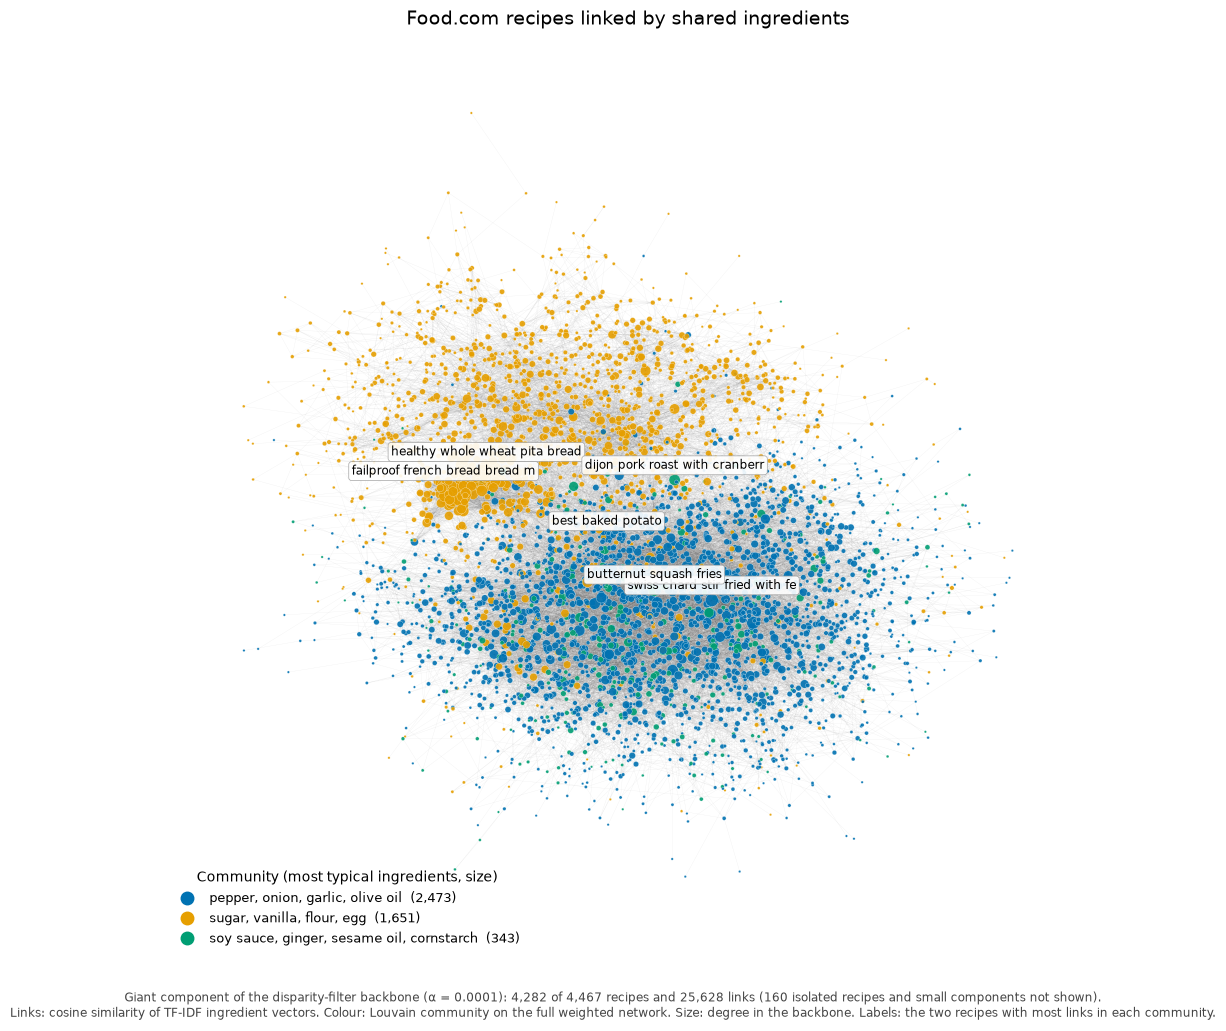

In [63]:
import matplotlib.pyplot as plt

# Force layout of the backbone's giant component
Gc = G.subgraph(giant)
nodes = list(Gc)
g_back = ig.Graph.from_networkx(Gc)
layout = g_back.layout_fruchterman_reingold(weights=[w for _, _, w in Gc.edges(data="weight")], niter=1000, seed=None)
pos = dict(zip(nodes, layout.coords))

degree = dict(Gc.degree())
# label the 2 recipes with most links in each community, so the reader can find their way in every group
top = [n for c in range(len(louvain))
       for n in sorted([n for n in nodes if community[n] == c], key=degree.get, reverse=True)[:2]]
palette = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00", "#F0E442", "#000000"]

fig, ax = plt.subplots(figsize=(12, 12))
nx.draw_networkx_edges(Gc, pos, ax=ax, width=0.2, alpha=0.1, edge_color="#555555")
nx.draw_networkx_nodes(Gc, pos, ax=ax, nodelist=nodes,
                       node_color=[palette[community[n] % len(palette)] for n in nodes],
                       node_size=[2 + degree[n] for n in nodes],
                       linewidths=0.2, edgecolors="white", alpha=0.9)
for n in top:
    ax.annotate(" ".join(name_of[n].split())[:30], pos[n], xytext=(0, 8), textcoords="offset points",
                fontsize=8.5, ha="center", bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="#999999", lw=0.5, alpha=0.9))

handles = [plt.Line2D([], [], marker="o", ls="", markersize=9, color=palette[c % len(palette)],
                      label=f"{labels[c]}  ({louvain.membership.count(c):,})") for c in range(len(louvain))]
ax.legend(handles=handles, title="Community (most typical ingredients, size)", loc="lower left", frameon=False, fontsize=9)
ax.set_title("Food.com recipes linked by shared ingredients", fontsize=14)
ax.axis("off")
fig.text(0.5, 0.06,
         f"Giant component of the disparity-filter backbone (α = {ALPHA:g}): {Gc.number_of_nodes():,} of {N:,} recipes and "
         f"{Gc.number_of_edges():,} links ({nx.number_of_isolates(G)} isolated recipes and small components not shown).\n"
         "Links: cosine similarity of TF-IDF ingredient vectors. Colour: Louvain community on the full weighted network. "
         "Size: degree in the backbone. Labels: the two recipes with most links in each community.",
         ha="center", fontsize=8.5, color="#444444")
plt.show()

## Step 9: Communities

Louvain (week 4) finds the number of communities itself, by moving recipes between groups until the modularity Q cannot get higher. But the **resolution** γ decides how big the groups become: Q = Σ [ ℓ_c/m − γ (d_c/2m)² ]. A higher γ punishes big groups more, so it gives more and smaller communities.

With the default γ = 1 we get only 3 very broad groups (savoury, sweet, Asian-style). We use **γ = 1.5**, which splits them into types of dishes. We run Louvain on the **full** weighted network, not the backbone (week 4).

In [64]:
from sklearn.metrics import normalized_mutual_info_score

GAMMA = 1.5

random.seed(42)
part = g_full.community_multilevel(weights="weight", resolution=GAMMA)
Q_real = g_full.modularity(part.membership, weights="weight", resolution=GAMMA)
print(f"Louvain, gamma = {GAMMA}: {len(part)} communities, Q = {Q_real:.3f}")

for c in sorted(range(len(part)), key=lambda c: -len(part[c])):
    rows = np.array(part.membership) == c
    top = pd.Series(tfidf[rows].mean(axis=0), index=mlb.classes_).nlargest(5).index
    print(f"{rows.sum():5,} recipes: {', '.join(top)}")

Louvain, gamma = 1.5: 13 communities, Q = 0.138
1,084 recipes: vanilla, sugar, baking soda, baking powder, flour
  860 recipes: olive oil, parmesan cheese, garlic, parsley, pepper
  406 recipes: cumin, tomato, chili powder, onion, cilantro
  395 recipes: water, yeast, active yeast, sugar, bread flour
  370 recipes: cheddar cheese, bacon, sour cream, cream cheese, pepper
  349 recipes: soy sauce, ginger, sesame oil, cornstarch, garlic
  318 recipes: garlic powder, onion powder, paprika, cayenne pepper, pepper
  293 recipes: celery, carrot, potato, onion, chicken broth
  236 recipes: ketchup, worcestershire sauce, onion soup mix, cream of mushroom soup, brown sugar
   67 recipes: milk, flour, egg, vegetable oil, pepper
   43 recipes: bread, heavy cream, butter, egg, mayonnaise
   41 recipes: lemon juice, sugar, nutmeg, cinnamon, apple
    5 recipes: m&m's chocolate candy, hershey chocolate kisses, pretzel, hershey's hugs chocolates, fudge-striped shortbread cookies


Save the communities, so `reviews.ipynb` can compare them (both the γ = 1.5 communities and the 3 broad γ = 1 communities used in the drawing).

In [65]:
pd.DataFrame({"id": recipes["id"],
              "community": part.membership,           # gamma = 1.5
              "community_broad": louvain.membership,  # gamma = 1
              }).to_parquet("data/communities.parquet")
print("Saved data/communities.parquet")

Saved data/communities.parquet


### Check 1: stability across seeds

Louvain visits the recipes in a random order, so two runs can give different communities (week 4). We run it 10 times with different seeds and compare every pair of runs with NMI (1 = identical, 0 = nothing in common).

In [66]:
from itertools import combinations

runs = []
for seed in range(10):
    random.seed(seed)
    p = g_full.community_multilevel(weights="weight", resolution=GAMMA)
    runs.append(p.membership)
    print(f"seed {seed}: {len(p)} communities, Q = {g_full.modularity(p.membership, weights='weight', resolution=GAMMA):.3f}")

nmis = [normalized_mutual_info_score(a, b) for a, b in combinations(runs, 2)]
print(f"\nNMI between runs: mean {np.mean(nmis):.2f}, min {np.min(nmis):.2f}, max {np.max(nmis):.2f}")

seed 0: 15 communities, Q = 0.136
seed 1: 15 communities, Q = 0.138
seed 2: 15 communities, Q = 0.135
seed 3: 12 communities, Q = 0.135
seed 4: 16 communities, Q = 0.136
seed 5: 14 communities, Q = 0.136
seed 6: 13 communities, Q = 0.135
seed 7: 13 communities, Q = 0.137
seed 8: 16 communities, Q = 0.135
seed 9: 15 communities, Q = 0.138

NMI between runs: mean 0.70, min 0.59, max 0.85


### Check 2: null model

Even a random network gets Q > 0, because Louvain always finds *some* groups (week 4). So we compare with a null model.

Our network is built from ingredient lists, so the null model shuffles the **ingredients**: every recipe keeps its number of ingredients, and every ingredient keeps the number of recipes it is used in. This is the degree-preserving shuffle from week 2, done on the recipe–ingredient data. We use the *curveball* algorithm: pick two recipes, pool the ingredients that only one of them has, and deal them out again at random (each recipe gets back as many as it gave).

Then we build TF-IDF, cosine and Louvain exactly as for the real data, and compare Q. (This cell takes some minutes: 20 networks with about 6 million links each.) If the real Q is much higher, the communities are about *which ingredients go together*, not just about how common the ingredients are.

In [67]:
def curveball(lists, n_trades, rng):
    lists = [set(x) for x in lists]
    for _ in range(n_trades):
        a, b = rng.choice(len(lists), 2, replace=False)
        only_a, only_b = lists[a] - lists[b], lists[b] - lists[a]
        pool = list(only_a | only_b)
        rng.shuffle(pool)
        new_a = set(pool[:len(only_a)])
        lists[a] = (lists[a] - only_a) | new_a
        lists[b] = (lists[b] - only_b) | (set(pool) - new_a)
    return [sorted(x) for x in lists]


def build_full_graph(ingredient_lists):
    Xn = mlb.transform(ingredient_lists)           # same columns as the real data
    T = Xn * np.log(N / Xn.sum(axis=0))            # df is the same as in the real data
    T = T / np.linalg.norm(T, axis=1, keepdims=True)
    Sn = T @ T.T
    a, b = np.where(np.triu(Sn, k=1) > 0)
    return ig.Graph(n=N, edges=np.column_stack([a, b]), edge_attrs={"weight": Sn[a, b]})


rng = np.random.default_rng(0)
Q_null = []
for r in range(20):
    shuffled = curveball(recipes["ingr_clean"], n_trades=10 * N, rng=rng)
    gn = build_full_graph(shuffled)
    random.seed(r)
    pn = gn.community_multilevel(weights="weight", resolution=GAMMA)
    Q_null.append(gn.modularity(pn.membership, weights="weight", resolution=GAMMA))

Q_null = np.array(Q_null)
z = (Q_real - Q_null.mean()) / Q_null.std()
print(f"Real Q:  {Q_real:.3f}")
print(f"Null Q:  {Q_null.mean():.3f} ± {Q_null.std():.3f}  (20 shuffles, min {Q_null.min():.3f}, max {Q_null.max():.3f})")
print(f"z-score: {z:.0f}")

Real Q:  0.138
Null Q:  0.061 ± 0.001  (20 shuffles, min 0.059, max 0.062)
z-score: 91


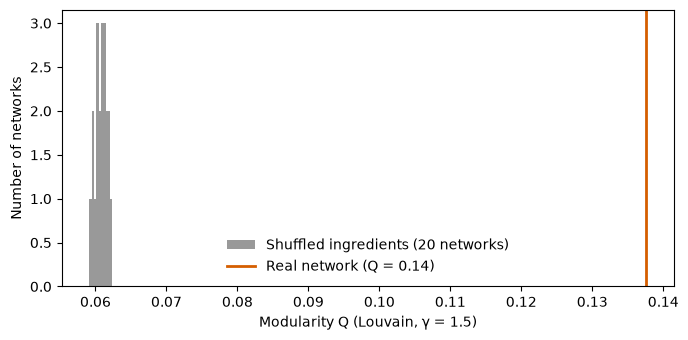

In [68]:
plt.figure(figsize=(7, 3.5))
plt.hist(Q_null, bins=10, color="#999999", label="Shuffled ingredients (20 networks)")
plt.axvline(Q_real, color="#D55E00", lw=2, label=f"Real network (Q = {Q_real:.2f})")
plt.xlabel(f"Modularity Q (Louvain, γ = {GAMMA})")
plt.ylabel("Number of networks")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

### What the checks show

**The communities are real structure (null model).** The real network has Q = 0.138, the 20 shuffled networks have Q = 0.061 ± 0.001 (z ≈ 100; the exact z changes a little between runs because the shuffles are random). So the shuffled networks also get Q > 0, as week 4 warns, but the real Q is more than twice as high. The groups come from *which ingredients are used together*, not only from how common the ingredients are.

**They are only moderately stable (seeds).** Between runs the number of communities goes from 12 to 16, Q hardly changes (0.135–0.138), and the NMI between runs is 0.70 on average (0.59–0.85). In the words of week 4: the core of the groups is stable, but the borders move. This is the flat modularity landscape: many different partitions have almost the same Q.

**What the 13 communities are** (our interpretation of the top ingredients, not the model's output): baking and sweets, Mediterranean/Italian (olive oil, parmesan), Mexican (cumin, chili powder, cilantro), yeast bread, cheese-and-bacon comfort food, Asian-style, spice rubs (garlic powder, paprika, cayenne), soups and stews (celery, carrot, potato, broth), American casseroles (ketchup, onion soup mix, cream of mushroom soup), plus some small groups. The smallest (5 recipes) is candy (m&m's, hershey kisses, pretzels).

**How to report it:** "Louvain (γ = 1.5) on the full network finds 12–16 communities across 10 seeds (NMI 0.59–0.85 between runs), with Q = 0.138 against 0.061 ± 0.001 for 20 ingredient-shuffled networks."

### Final community plot

13 communities, disparity filter as backbone (26.000 links), colored by communuity from the entire network (6.1 links).

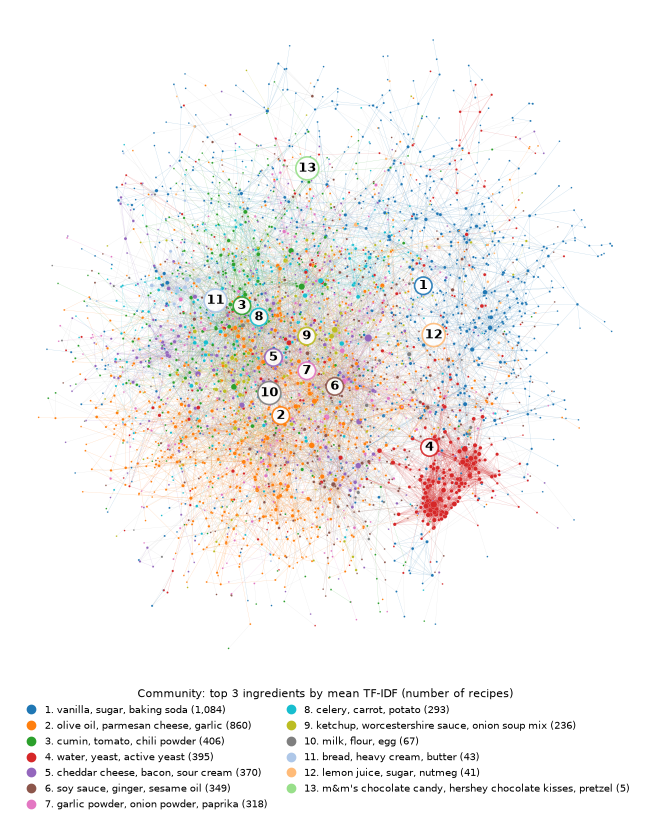

Shown: giant component of the backbone (α = 1e-05), 3,650 of 4,467 recipes, 10,752 links (56% inside a community)


In [76]:
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D

# Communities: Louvain, gamma = 1.5, on the full weighted network (Step 9)
comm = dict(zip(recipes["id"], part.membership))
order = sorted(range(len(part)), key=lambda c: -len(part[c]))       # largest community first = number 1
number = {c: k + 1 for k, c in enumerate(order)}

# 13 colours that can be told apart (tab10 + 3 light ones for the smallest communities)
colours = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2",
           "#17becf", "#bcbd22", "#7f7f7f", "#aec7e8", "#ffbb78", "#98df8a"]
colour_of = {c: colours[k % len(colours)] for k, c in enumerate(order)}

# Name each community after its 3 ingredients with the highest mean TF-IDF
names = {}
for c in order:
    rows = np.array(part.membership) == c
    names[c] = ", ".join(pd.Series(tfidf[rows].mean(axis=0), index=mlb.classes_).nlargest(3).index)

# Force layout of the backbone's giant component, with a fixed seed so the figure is the same every run
Gc = G.subgraph(giant)
g_back = ig.Graph.from_networkx(Gc)
random.seed(1)
layout = g_back.layout_fruchterman_reingold(weights=g_back.es["weight"], niter=2000)
pos = dict(zip(g_back.vs["_nx_name"], layout.coords))

fig, ax = plt.subplots(figsize=(7.2, 8.6))

# Links: grey between communities, coloured inside a community
between = [(u, v) for u, v in Gc.edges() if comm[u] != comm[v]]
within = [(u, v) for u, v in Gc.edges() if comm[u] == comm[v]]
ax.add_collection(LineCollection([(pos[u], pos[v]) for u, v in between],
                                 colors="#9a9a9a", linewidths=0.15, alpha=0.25, zorder=1))
ax.add_collection(LineCollection([(pos[u], pos[v]) for u, v in within],
                                 colors=[colour_of[comm[u]] for u, _ in within], linewidths=0.2, alpha=0.3, zorder=2))

# Nodes in random order, so no community is hidden under another; size = degree in the backbone
degree = dict(Gc.degree())
nodes = list(np.random.default_rng(0).permutation(list(Gc)))
xy = np.array([pos[n] for n in nodes])
ax.scatter(xy[:, 0], xy[:, 1], s=[1 + 0.35 * degree[n] for n in nodes], c=[colour_of[comm[n]] for n in nodes],
           linewidths=0.1, edgecolors="white", zorder=3)

# Community number on the member closest to the community's median position (so it never floats in empty space)
for c in order:
    members = np.array([pos[n] for n in Gc if comm[n] == c])
    if len(members):
        x, y = members[np.argmin(np.linalg.norm(members - np.median(members, axis=0), axis=1))]
        ax.text(x, y, str(number[c]), fontsize=9, fontweight="bold", ha="center", va="center", zorder=4,
                bbox=dict(boxstyle="circle,pad=0.2", fc="white", ec=colour_of[c], lw=1.2, alpha=0.9))

ax.set_aspect("equal")
ax.autoscale()
ax.axis("off")

handles = [Line2D([], [], marker="o", ls="", markersize=6, color=colour_of[c],
                  label=f"{number[c]}. {names[c]} ({len(part[c]):,})") for c in order]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2, frameon=False,
          fontsize=7.5, handletextpad=0.3, columnspacing=1.2,
          title="Community: top 3 ingredients by mean TF-IDF (number of recipes)", title_fontsize=8)

plt.tight_layout()
os.makedirs("figures", exist_ok=True)
fig.savefig("figures/backbone_13_communities.pdf", bbox_inches="tight")
fig.savefig("figures/backbone_13_communities.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Shown: giant component of the backbone (α = {ALPHA:g}), {Gc.number_of_nodes():,} of {N:,} recipes, "
      f"{Gc.number_of_edges():,} links ({len(within) / Gc.number_of_edges():.0%} inside a community)")

Sweet baking (1,084 recipes)
   top ingredients: vanilla, sugar, baking soda, baking powder, flour, egg, cinnamon, butter
   most reviewed:   best banana bread | best ever banana cake with cream cheese frosting | whatever floats your boat brownies | banana banana bread
Italian & Mediterranean (860 recipes)
   top ingredients: olive oil, parmesan cheese, garlic, parsley, pepper, basil, lemon juice, oregano
   most reviewed:   creamy cajun chicken pasta | jo mama s world famous spaghetti | kittencal s italian melt in your mouth meatballs | olive garden copycat zuppa toscana
Mexican & Tex-Mex (406 recipes)
   top ingredients: cumin, tomato, chili powder, onion, cilantro, garlic, jalapeno, salsa
   most reviewed:   crock pot chicken with black beans cream cheese | creamy burrito casserole | oven fried chicken chimichangas | simply sour cream chicken enchiladas
Yeast bread & dough (395 recipes)
   top ingredients: water, yeast, active yeast, sugar, bread flour, vegetable oil, flour, egg
   

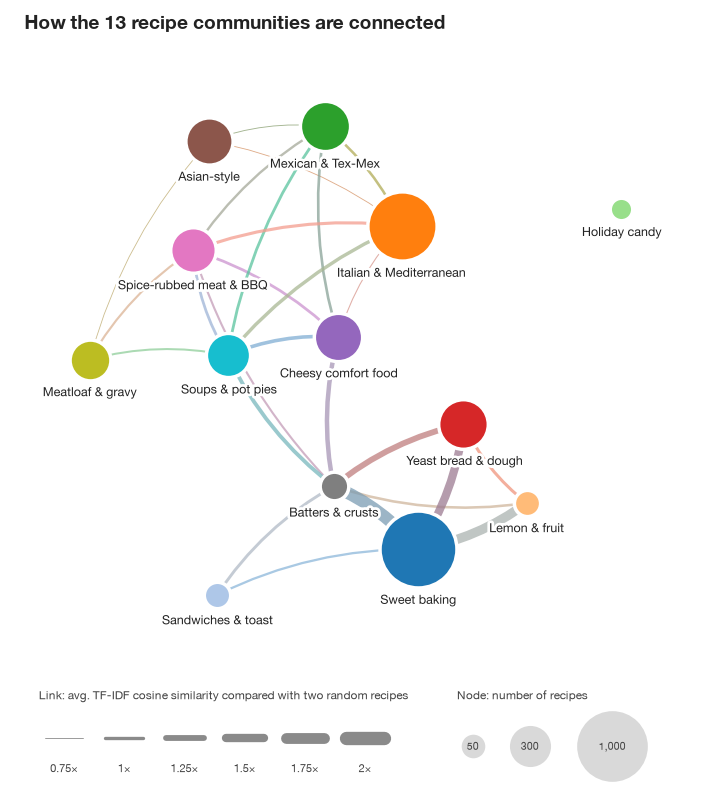

26 of 78 links drawn (at least 0.75× as similar as two random recipes)

Average similarity between communities, × two random recipes (diagonal = inside the community):


,Sweet baking,Italian & Mediterranean,Mexican & Tex-Mex,Yeast bread & dough,Cheesy comfort food,Asian-style,Spice-rubbed meat & BBQ,Soups & pot pies,Meatloaf & gravy,Batters & crusts,Sandwiches & toast,Lemon & fruit,Holiday candy
Sweet baking,3.65,0.34,0.33,1.48,0.66,0.55,0.53,0.56,0.54,1.90,0.90,1.60,0.05
Italian & Mediterranean,0.34,2.02,0.92,0.46,0.77,0.75,0.98,1.01,0.65,0.68,0.55,0.73,0.00
Mexican & Tex-Mex,0.33,0.92,2.33,0.44,0.93,0.76,0.90,0.95,0.69,0.55,0.43,0.46,0.00
Yeast bread & dough,1.48,0.46,0.44,2.71,0.49,0.68,0.58,0.66,0.58,1.25,0.49,0.97,0.01
Cheesy comfort food,0.66,0.77,0.93,0.49,2.37,0.47,0.94,1.02,0.73,1.11,0.71,0.58,0.00
Asian-style,0.55,0.75,0.76,0.68,0.47,2.87,0.73,0.73,0.75,0.46,0.35,0.68,0.00
Spice-rubbed meat & BBQ,0.53,0.98,0.90,0.58,0.94,0.73,2.85,0.94,0.88,0.88,0.54,0.50,0.03
Soups & pot pies,0.56,1.01,0.95,0.66,1.02,0.73,0.94,2.74,0.87,1.05,0.68,0.48,0.00
Meatloaf & gravy,0.54,0.65,0.69,0.58,0.73,0.75,0.88,0.87,1.87,0.70,0.50,0.55,0.02
Batters & crusts,1.90,0.68,0.55,1.25,1.11,0.46,0.88,1.05,0.70,3.45,0.96,0.92,0.00


In [89]:
from itertools import combinations
from matplotlib import colors as mcolors
from matplotlib import patheffects as pe
from matplotlib.patches import FancyArrowPatch

# Community graph: each Louvain community (gamma = 1.5) is one node.
# Link A-B = average cosine similarity between a recipe in A and a recipe in B in the FULL network,
# divided by the average similarity of all pairs (1 = as similar as two random recipes).
# Dividing by the number of pairs keeps the big communities from looking connected to everything just because they are big.
membership = np.array(part.membership)
by_size = sorted(range(len(part)), key=lambda c: -len(part[c]))
colours = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2",
           "#17becf", "#bcbd22", "#7f7f7f", "#aec7e8", "#ffbb78", "#98df8a"]
colour_of = {c: colours[k % len(colours)] for k, c in enumerate(by_size)}   # same colours as the other figures

# Titles: our interpretation of each community, found by a marker ingredient among its top 3 (by mean TF-IDF).
# Matching on an ingredient instead of the community number keeps the titles right if Louvain numbers them differently.
TITLES = {"vanilla": "Sweet baking", "parmesan cheese": "Italian & Mediterranean", "cumin": "Mexican & Tex-Mex",
          "yeast": "Yeast bread & dough", "cheddar cheese": "Cheesy comfort food", "soy sauce": "Asian-style",
          "garlic powder": "Spice-rubbed meat & BBQ", "celery": "Soups & pot pies", "ketchup": "Meatloaf & gravy",
          "milk": "Batters & crusts", "bread": "Sandwiches & toast", "lemon juice": "Lemon & fruit",
          "m&m's chocolate candy": "Holiday candy"}

title, top_ingredients = {}, {}
for c in by_size:
    rows = membership == c
    top_ingredients[c] = pd.Series(tfidf[rows].mean(axis=0), index=mlb.classes_).nlargest(8).index
    match = [TITLES[x] for x in top_ingredients[c][:3] if x in TITLES]
    title[c] = match[0] if match else ", ".join(top_ingredients[c][:2])   # fallback: no marker found

# Print the evidence for each title, so it can be checked by hand
for c in by_size:
    rows = membership == c
    examples = recipes.loc[rows].nlargest(4, "n_reviews")["name"].str.split().str.join(" ")
    print(f"{title[c]} ({rows.sum():,} recipes)\n   top ingredients: {', '.join(top_ingredients[c])}"
          f"\n   most reviewed:   {' | '.join(examples)}")
print()

M = np.eye(len(part))[membership]                  # recipes x communities, 1 = member
total = M.T @ S @ M                                  # summed similarity between (and inside) communities
n = M.sum(axis=0).astype(int)
pairs = np.outer(n, n) - np.diag(n)                  # inside a community: n(n-1) ordered pairs (S has 0 on the diagonal)
lift = (total / pairs) / (S.sum() / (N * (N - 1)))

CG = nx.Graph()
CG.add_nodes_from(by_size)
for a, b in combinations(by_size, 2):
    CG.add_edge(a, b, lift=lift[a, b])

# Layout: distance between two communities = 1 / similarity, so similar communities lie close together.
# Capped at 1 / 0.5, otherwise the candy community (almost no similarity to anything) is pushed far away.
dist = {a: {b: 1 / max(lift[a, b], 0.5) for b in by_size if b != a} for a in by_size}
pos = nx.kamada_kawai_layout(CG, dist=dist)

# Links: only those of at least 0.75x random. Width is a fixed scale, so the legend is exact.
MIN_LIFT, MAX_LIFT = 0.75, 2.0


def link_width(w):
    return 0.6 + 9 * (min(w, MAX_LIFT) - MIN_LIFT) / (MAX_LIFT - MIN_LIFT)


def blend(a, b):
    """The colour halfway between two communities, lightened a little."""
    mix = (np.array(mcolors.to_rgb(colour_of[a])) + np.array(mcolors.to_rgb(colour_of[b]))) / 2
    return tuple(0.75 * mix + 0.25)


def node_size(count):
    return 250 + 2.6 * count            # marker area in points^2


edges = sorted([e for e in CG.edges(data="lift") if e[2] >= MIN_LIFT], key=lambda e: e[2])   # strongest on top

with plt.rc_context({"font.family": ["Helvetica Neue", "Arial", "DejaVu Sans"]}):
    fig = plt.figure(figsize=(7.2, 8.0))
    ax = fig.add_axes([0.02, 0.14, 0.96, 0.78])
    leg = fig.add_axes([0.06, 0.0, 0.88, 0.15])
    fig.text(0.04, 0.985, "How the 13 recipe communities are connected", fontsize=14, fontweight="bold",
             color="#222222", va="top")
    for a, b, w in edges:
        ax.add_patch(FancyArrowPatch(pos[a], pos[b], arrowstyle="-", connectionstyle="arc3,rad=0.12",
                                     lw=link_width(w), color=blend(a, b), alpha=0.75, capstyle="round",
                                     shrinkA=0, shrinkB=0, zorder=1))

    for c in by_size:
        ax.scatter(*pos[c], s=node_size(n[c]), color=colour_of[c], edgecolors="white", linewidths=2.5, zorder=2)

    # Titles directly below each node, with a white halo so links never run through the text
    for c in by_size:
        gap = np.sqrt(node_size(n[c])) / 2 + 3                     # node radius + 3 points
        ax.annotate(title[c], pos[c], xytext=(0, -gap), textcoords="offset points", ha="center", va="top",
                    fontsize=9, color="#222222", zorder=3,
                    path_effects=[pe.withStroke(linewidth=4, foreground="white")])

    xy = np.array(list(pos.values()))
    span = (xy.max(axis=0) - xy.min(axis=0)).max()
    ax.set_xlim(xy[:, 0].min() - 0.15 * span, xy[:, 0].max() + 0.15 * span)
    ax.set_ylim(xy[:, 1].min() - 0.12 * span, xy[:, 1].max() + 0.07 * span)
    ax.set_aspect("equal")
    ax.axis("off")

    # Legend panel: link width (left) and node size (right)
    leg.set_xlim(0, 10)
    leg.set_ylim(0, 3)
    leg.axis("off")
    leg.text(0, 2.75, "Link: avg. TF-IDF cosine similarity compared with two random recipes", fontsize=8.5, color="#444444", va="top")
    for k, w in enumerate([0.75, 1.0, 1.25, 1.5, 1.75, 2.0]):
        x = 0.1 + k * 0.95
        leg.plot([x, x + 0.6], [1.5, 1.5], lw=link_width(w), color="#8a8a8a", solid_capstyle="round")
        leg.text(x + 0.3, 0.75, f"{w:g}×", fontsize=8, color="#444444", ha="center", va="center")

    leg.text(6.6, 2.75, "Node: number of recipes", fontsize=8.5, color="#444444", va="top")
    for k, (count, x) in enumerate([(50, 6.85), (300, 7.75), (1000, 9.05)]):
        leg.scatter(x, 1.3, s=node_size(count), color="#d9d9d9", edgecolors="white", linewidths=2.5)
        leg.text(x, 1.3, f"{count:,}", fontsize=7.5, color="#444444", ha="center", va="center")

    os.makedirs("figures", exist_ok=True)
    fig.savefig("figures/community_graph.pdf", bbox_inches="tight")
    fig.savefig("figures/community_graph.png", dpi=300, bbox_inches="tight")
    plt.show()

print(f"{len(edges)} of {CG.number_of_edges()} links drawn (at least {MIN_LIFT}× as similar as two random recipes)")

# The numbers behind the figure (diagonal = inside the community)
table = pd.DataFrame(lift, index=[title[c] for c in range(len(part))], columns=[title[c] for c in range(len(part))])
table = table.loc[[title[c] for c in by_size], [title[c] for c in by_size]]
print("\nAverage similarity between communities, × two random recipes (diagonal = inside the community):")
table.round(2)